# Banana Ripeness Classification — MobileNetV2 + HSV

**Notebook implementasi UAS Deep Learning (sesuai proposal final)**

Tugas: klasifikasi **empat tingkat kematangan** pisang dari gambar, **bukan** pendeteksian bounding box.

**Eksperimen**
1. MobileNetV2 pretrained ImageNet (baseline).
2. MobileNetV2 + augmentasi kecerahan, gamma, dan saturasi.
3. MobileNetV2 + fitur histogram HSV (16 bin per kanal = 48 fitur) + augmentasi.

Setiap eksperimen menggunakan split train/validation/test yang sama. `macro-F1` dipakai sebagai metrik utama. Training dua tahap: train classification head, lalu fine-tune sebagian lapisan akhir MobileNetV2. Ada mode **QUICK_RUN** untuk mengecek kode sebelum menjalankan eksperimen tiga seed.

> Hasil metrik tidak diisi atau direkayasa. Angka baru diperoleh setelah training pada dataset asli dijalankan.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Google Colab dan dependensi
Pilih **Runtime → Change runtime type → GPU**. TensorFlow sudah tersedia di sebagian besar runtime Colab. Library lain dipasang jika diperlukan.

In [ ]:
%pip -q install scikit-learn matplotlib seaborn pandas

import os, re, time, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("PERINGATAN: GPU tidak terdeteksi. Training bisa lebih lambat.")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset resmi Pangestu (2023)

**Sumber:** [Banana Ripeness Image — Telkom University Dataverse](https://doi.org/10.34820/FK2/GJBZ0X).

Dataset yang digunakan pada proposal terdiri dari **1.490 data latih** dan **375 data uji**. Unduh ZIP asli dari halaman tersebut, kemudian unggah ke Colab. Notebook ini *mempertahankan test split resmi* dan mengambil 20% dari data latih sebagai validasi.

Jika dataset telah diekstrak melalui Google Drive, kamu bisa mengatur `DATA_ROOT` secara manual. ZIP diharapkan berisi direktori **train** dan **test**, masing-masing dengan empat subfolder label kelas. Jika strukturnya berbeda, baca pesan pada bagian identifikasi folder di bawah.

In [ ]:
from google.colab import files

DATA_ROOT = Path("/content/banana_ripeness_data")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Jika sudah diekstrak, sel upload ini boleh dilewati.
if not any(DATA_ROOT.iterdir()):
    print("Unggah ZIP resmi 'Banana Ripeness Image' dari Telkom University Dataverse.")
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if not zip_names:
        raise ValueError("ZIP dataset belum diunggah. Unggah ZIP lalu jalankan ulang.")
    with zipfile.ZipFile(zip_names[0], "r") as zf:
        # Tolak entri yang mencoba menulis di luar direktori ekstraksi.
        root = DATA_ROOT.resolve()
        for member in zf.infolist():
            target = (root / member.filename).resolve()
            if target != root and root not in target.parents:
                raise ValueError(f"Nama berkas ZIP tidak aman: {member.filename}")
        zf.extractall(root)

print("Isi teratas dataset:")
for p in sorted(DATA_ROOT.iterdir())[:30]:
    print(" -", p.relative_to(DATA_ROOT))

Unggah ZIP resmi 'Banana Ripeness Image' dari Telkom University Dataverse.


Saving Banana Ripeness Image.zip to Banana Ripeness Image.zip
Isi teratas dataset:
 - test
 - train


## 3. Temukan train/test dan periksa label

Kode akan mencoba mencari folder yang bernama `train` dan `test` (atau variasinya). Bila data memiliki nama folder berbeda, isi `TRAIN_DIR` dan `TEST_DIR` secara manual. Urutan label diambil **dari folder asli**; periksa agar sesuai dengan empat tingkat kematangan yang dimaksud pada proposal.

In [ ]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def has_images(folder):
    return any(p.is_file() and p.suffix.lower() in IMAGE_EXTS for p in folder.rglob("*"))

def get_class_folders(split_dir):
    if split_dir is None or not split_dir.exists():
        return {}
    return {p.name: p for p in split_dir.iterdir() if p.is_dir() and has_images(p)}

def search_split(root, kind):
    possibilities = []
    for p in [root] + list(root.rglob("*")):
        if not p.is_dir():
            continue
        name = re.sub(r"[^a-z]", "", p.name.lower())
        name_match = ("train" in name) if kind == "train" else ("test" in name or "testing" in name)
        if name_match and len(get_class_folders(p)) == 4:
            possibilities.append(p)
    return sorted(possibilities, key=lambda p: len(p.parts))[0] if possibilities else None

TRAIN_DIR = search_split(DATA_ROOT, "train")
TEST_DIR = search_split(DATA_ROOT, "test")

print("TRAIN_DIR =", TRAIN_DIR)
print("TEST_DIR  =", TEST_DIR)
if TRAIN_DIR is None or TEST_DIR is None:
    print("\nContoh struktur folder pada ZIP:")
    for p in list(DATA_ROOT.rglob("*"))[:45]:
        print(" -", p.relative_to(DATA_ROOT))
    raise FileNotFoundError(
        "Folder train/test yang berisi empat subfolder kelas belum ditemukan. "
        "Periksa struktur ZIP, lalu atur TRAIN_DIR dan TEST_DIR ke folder yang benar."
    )

train_class_folders = get_class_folders(TRAIN_DIR)
test_class_folders = get_class_folders(TEST_DIR)
CLASS_NAMES = sorted(train_class_folders.keys(), key=str.lower)
if len(CLASS_NAMES) != 4 or set(CLASS_NAMES) != set(test_class_folders):
    raise ValueError("Label train dan test harus berisi empat nama folder kelas yang sama.")

class_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}
print("Urutan label (periksa dengan isi dataset resmi):", class_to_idx)

def collect_images(folder_map):
    records=[]
    for label, directory in folder_map.items():
        for p in sorted(directory.rglob("*")):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
                records.append({"path": str(p.resolve()), "class_name": label,
                                "target": class_to_idx[label]})
    return pd.DataFrame(records)

full_train_df = collect_images(train_class_folders)
test_df = collect_images(test_class_folders)
print("\nDataset resmi:", len(full_train_df), "train;", len(test_df), "test")
print("\nDistribusi train:")
print(full_train_df.class_name.value_counts().reindex(CLASS_NAMES, fill_value=0))
print("\nDistribusi test:")
print(test_df.class_name.value_counts().reindex(CLASS_NAMES, fill_value=0))
if (len(full_train_df), len(test_df)) != (1490, 375):
    print("PERINGATAN: jumlahnya tidak sama dengan proposal (1.490 train, 375 test). "
          "Pastikan ZIP yang digunakan benar.")

TRAIN_DIR = /content/banana_ripeness_data/train
TEST_DIR  = /content/banana_ripeness_data/test
Urutan label (periksa dengan isi dataset resmi): {'matang': 0, 'mentah': 1, 'setengah-matang': 2, 'terlalu-matang': 3}

Dataset resmi: 1490 train; 375 test

Distribusi train:
class_name
matang             235
mentah             392
setengah-matang    484
terlalu-matang     379
Name: count, dtype: int64

Distribusi test:
class_name
matang              59
mentah              99
setengah-matang    122
terlalu-matang      95
Name: count, dtype: int64


## 4. Buat validasi dari data latih dan cek kebocoran data

Validation split dibuat **stratified** dengan seed tetap. Test split resmi **tidak** digunakan untuk memilih hyperparameter maupun checkpoint.

In [ ]:
train_df, val_df = train_test_split(
    full_train_df, test_size=0.20, stratify=full_train_df["target"], random_state=42
)
train_df = train_df.sort_values("path").reset_index(drop=True)
val_df = val_df.sort_values("path").reset_index(drop=True)
test_df = test_df.sort_values("path").reset_index(drop=True)

assert set(train_df.path).isdisjoint(val_df.path)
assert set(train_df.path).isdisjoint(test_df.path)
assert set(val_df.path).isdisjoint(test_df.path)
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print(pd.DataFrame({
    "train": train_df.class_name.value_counts(),
    "validation": val_df.class_name.value_counts(),
    "test": test_df.class_name.value_counts()
}).fillna(0).astype(int).reindex(CLASS_NAMES))

# Catatan: cek juga apakah ada foto yang sangat mirip atau foto pisang yang sama
# di beberapa split. Pemisahan berdasarkan foto saja tidak selalu menghilangkan leakage.

Train: 1192, Val: 298, Test: 375
                 train  validation  test
class_name                              
matang             188          47    59
mentah             314          78    99
setengah-matang    387          97   122
terlalu-matang     303          76    95


## 5. Data pipeline dan histogram HSV (48 fitur)

Gambar dibaca dalam rentang `[0,1]`, lalu ditransformasikan ke `[-1,1]` **di dalam model**, sesuai kebutuhan MobileNetV2. Histogram HSV dihitung dari gambar dalam rentang `[0,1]` **sebelum preprocessing MobileNetV2**. Pada eksperimen beraugmentasi, histogram dihitung dari **gambar hasil augmentasi yang sama** dengan input CNN.

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

# Histogram 16 bin H, 16 bin S, 16 bin V = 48 fitur.
def hsv_histogram(image_01):
    hsv = tf.image.rgb_to_hsv(image_01)
    bins = []
    for channel in tf.unstack(hsv, axis=-1):
        h = tf.histogram_fixed_width(channel, value_range=[0.0, 1.0], nbins=16)
        bins.append(tf.cast(h, tf.float32) / tf.cast(tf.size(channel), tf.float32))
    result = tf.concat(bins, axis=0)
    result.set_shape((48,))
    return result

def read_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.clip_by_value(tf.cast(image, tf.float32) / 255.0, 0.0, 1.0)
    return image, tf.cast(label, tf.int32)

def lighting_augmentation(image):
    image = tf.image.random_brightness(image, max_delta=0.12)
    image = tf.clip_by_value(image, 0.0, 1.0)
    image = tf.image.random_saturation(image, lower=0.80, upper=1.20)
    image = tf.clip_by_value(image, 0.0, 1.0)
    gamma = tf.random.uniform([], minval=0.85, maxval=1.15)
    image = tf.pow(tf.clip_by_value(image, 0.0, 1.0), gamma)
    return tf.clip_by_value(image, 0.0, 1.0)

def make_dataset(df, augment=False, use_hsv=False, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].astype(str).to_numpy(), df["target"].astype("int32").to_numpy())
    )
    if training:
        ds = ds.shuffle(len(df), reshuffle_each_iteration=True)
    ds = ds.map(read_image, num_parallel_calls=AUTOTUNE)
    if augment and training:
        ds = ds.map(lambda image, label: (lighting_augmentation(image), label),
                    num_parallel_calls=AUTOTUNE)
    if use_hsv:
        ds = ds.map(lambda image, label: (
            {"image_input": image, "hsv_input": hsv_histogram(image)}, label
        ), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Cek satu batch, sebelum training.
example_ds = make_dataset(train_df, use_hsv=True)
features, target = next(iter(example_ds))
print("Batch gambar:", features["image_input"].shape)
print("Batch HSV:", features["hsv_input"].shape)
print("Batch label:", target.shape)
assert features["hsv_input"].shape[-1] == 48

Batch gambar: (16, 224, 224, 3)
Batch HSV: (16, 48)
Batch label: (16,)


## 6. Arsitektur MobileNetV2 dan gabungan HSV

Pada skenario ketiga, fitur hasil `GlobalAveragePooling2D` dari MobileNetV2 digabungkan dengan **48 fitur HSV** menggunakan `Concatenate`. BatchNormalization pada backbone dipertahankan pada inference mode ketika fine-tuning, mengikuti panduan transfer learning TensorFlow.

In [ ]:
def build_model(use_hsv=False):
    image_input = keras.Input(shape=(*IMG_SIZE, 3), name="image_input")
    # Sama dengan MobileNetV2 preprocess_input untuk piksel yang sudah di [0, 1].
    x = layers.Rescaling(2.0, offset=-1.0, name="mobilenet_scaling")(image_input)
    base = tf.keras.applications.MobileNetV2(
        include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
    )
    base.trainable = False
    features = base(x, training=False)
    features = layers.GlobalAveragePooling2D(name="global_avg")(features)

    if use_hsv:
        hist_input = keras.Input(shape=(48,), name="hsv_input")
        features = layers.Concatenate(name="feature_concat")([features, hist_input])
        model_inputs = [image_input, hist_input]
    else:
        model_inputs = image_input

    x = layers.Dense(128, activation="relu", name="dense_128")(features)
    x = layers.Dropout(0.30, name="dropout_head")(x)
    output = layers.Dense(4, activation="softmax", name="class_probs")(x)
    model = keras.Model(model_inputs, output, name="banana_ripeness_classifier")
    return model, base

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

model_preview, backbone_preview = build_model(use_hsv=True)
model_preview.summary()
del model_preview, backbone_preview
keras.backend.clear_session()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "banana_ripeness_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_scaling   │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ mobilenet_scalin… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg          │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hsv_input           │ (None, 48)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_concat      │ (None, 1328)      │          0 │ global_avg[0][0], │
│ (Concatenate)       │                   │            │ hsv_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │    170,112 │ feature_concat[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_head        │ (None, 128)       │          0 │ dense_128[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_probs (Dense) │ (None, 4)         │        516 │ dropout_head[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,428,612 (9.26 MB)

 Trainable params: 170,628 (666.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Konfigurasi eksperimen

Gunakan `QUICK_RUN=True` **hanya untuk memastikan notebook dapat dijalankan**. Untuk pengambilan hasil UAS, ubah menjadi `False`, sehingga seluruh tiga model diuji pada **3 random seed** (total 9 konfigurasi training). Angka epoch di bawah merupakan titik awal yang boleh disesuaikan berdasarkan validation loss, tidak menjamin metrik tertentu.

In [ ]:
QUICK_RUN = False  # UBAH ke False untuk hasil eksperimen final UAS
SEEDS = [42] if QUICK_RUN else [42, 123, 2026]
HEAD_EPOCHS = 2 if QUICK_RUN else 12
FINETUNE_EPOCHS = 2 if QUICK_RUN else 12
PATIENCE = 2 if QUICK_RUN else 4
FINE_TUNE_LAST_N = 30
# RUN_DIR = Path("/content/banana_mobilenet_runs")
# RUN_DIR.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(
    "/content/drive/MyDrive/Deep Learning/UAS"
)
RUN_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = [
    {"name": "A_baseline", "augment": False, "use_hsv": False},
    {"name": "B_augmentation", "augment": True, "use_hsv": False},
    {"name": "C_augmentation_hsv", "augment": True, "use_hsv": True},
]

classes = np.arange(len(CLASS_NAMES))
weights = compute_class_weight("balanced", classes=classes, y=train_df.target.to_numpy())
CLASS_WEIGHTS = {int(i): float(w) for i, w in zip(classes, weights)}
print("Class weights:", CLASS_WEIGHTS)
if QUICK_RUN:
    print("MODE PENGECEKAN: hasil dari QUICK_RUN tidak boleh diklaim sebagai hasil final.")

Class weights: {0: 1.5851063829787233, 1: 0.9490445859872612, 2: 0.7700258397932817, 3: 0.9834983498349835}


## 8. Training dua tahap + pemilihan checkpoint dengan validation macro-F1

**Tahap 1:** backbone frozen, classification head dilatih. **Tahap 2:** 30 layer terakhir backbone dibuka (kecuali BatchNormalization) dengan learning rate lebih kecil. Checkpoint terbaik dari masing-masing tahap dibandingkan pada **validation set**; yang macro-F1 validasinya lebih baik dipakai untuk evaluasi test. Dengan demikian fine-tuning tidak otomatis dianggap lebih baik.

In [ ]:
def macro_f1_for_model(model, df, use_hsv):
    eval_ds = make_dataset(df, augment=False, use_hsv=use_hsv, training=False)
    pred = model.predict(eval_ds, verbose=0).argmax(axis=1)
    return f1_score(df.target.to_numpy(), pred, average="macro", zero_division=0)

def run_experiment(exp, seed):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    run = RUN_DIR / f"{exp['name']}_seed{seed}"
    run.mkdir(parents=True, exist_ok=True)

    train_ds = make_dataset(train_df, augment=exp["augment"],
                            use_hsv=exp["use_hsv"], training=True)
    val_ds = make_dataset(val_df, use_hsv=exp["use_hsv"])

    model, base = build_model(use_hsv=exp["use_hsv"])
    compile_model(model, learning_rate=1e-3)
    head_path = run / "best_head.keras"
    cb1 = [
        keras.callbacks.ModelCheckpoint(str(head_path), monitor="val_loss",
                                        save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True)
    ]
    print(f"\n=== {exp['name']} | seed {seed} | head ===")
    history_head = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=cb1, verbose=1)

    # Fine-tune sebagian layer akhir, dengan BN tetap frozen.
    base.trainable = True
    for layer in base.layers:
        layer.trainable = False
    for layer in base.layers[-FINE_TUNE_LAST_N:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
    compile_model(model, learning_rate=1e-5)
    fine_path = run / "best_finetune.keras"
    cb2 = [
        keras.callbacks.ModelCheckpoint(str(fine_path), monitor="val_loss",
                                        save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                      restore_best_weights=True)
    ]
    print(f"=== {exp['name']} | seed {seed} | fine-tune ===")
    history_finetune = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS,
              class_weight=CLASS_WEIGHTS, callbacks=cb2, verbose=1)

    # Simpan kurva loss dan accuracy untuk analisis overfitting.
    head_history_df = pd.DataFrame(history_head.history)
    head_history_df["stage"] = "head"
    fine_history_df = pd.DataFrame(history_finetune.history)
    fine_history_df["stage"] = "fine_tune"
    pd.concat([head_history_df, fine_history_df], ignore_index=True).to_csv(
        run / "training_history.csv", index=False
    )

    # Jangan menggunakan test set untuk menentukan checkpoint terbaik.
    del model, base
    head_model = keras.models.load_model(head_path)
    head_f1 = macro_f1_for_model(head_model, val_df, exp["use_hsv"])
    del head_model
    finetuned_model = keras.models.load_model(fine_path)
    fine_f1 = macro_f1_for_model(finetuned_model, val_df, exp["use_hsv"])
    del finetuned_model
    chosen = head_path if head_f1 >= fine_f1 else fine_path
    print(f"Validation macro-F1: head={head_f1:.4f}, fine-tune={fine_f1:.4f}")
    print("Checkpoint terpilih:", chosen)

    # Evaluasi test hanya setelah pemilihan model pada validation.
    selected_model = keras.models.load_model(chosen)
    test_ds = make_dataset(test_df, use_hsv=exp["use_hsv"])
    probs = selected_model.predict(test_ds, verbose=0)
    pred = probs.argmax(axis=1)
    actual = test_df.target.to_numpy()

    # Estimasi waktu prediksi forward pass saja, tanpa membaca file dari disk.
    sample_batch = next(iter(test_ds))[0]
    _ = selected_model(sample_batch, training=False).numpy()  # warm-up
    t0 = time.perf_counter()
    for _ in range(10):
        _ = selected_model(sample_batch, training=False).numpy()
    elapsed = time.perf_counter() - t0
    batch_len = len(next(iter(test_ds))[1])
    infer_ms = elapsed * 1000 / (10 * batch_len)

    saved_model_path = run / "selected_model.keras"
    selected_model.save(saved_model_path)
    pd.DataFrame({"path": test_df.path, "true": actual, "pred": pred}).to_csv(
        run / "test_predictions.csv", index=False
    )
    return {
        "experiment": exp["name"], "seed": seed, "use_hsv": exp["use_hsv"],
        "checkpoint": str(saved_model_path),
        "val_macro_f1": max(head_f1, fine_f1),
        "accuracy": accuracy_score(actual, pred),
        "macro_f1": f1_score(actual, pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(actual, pred),
        "inference_ms_per_image": infer_ms
    }

## 9. Jalankan tiga skenario

**Perhatian:** `QUICK_RUN=False` menjalankan 3 skenario × 3 seed, dan setiap skenario mempunyai tahap head training dan fine-tuning. Jalankan di GPU. Jika waktu Colab tidak cukup, simpan notebook dan hasil ke Drive sebelum runtime berakhir.

In [ ]:
all_rows = []
for exp in EXPERIMENTS:
    for seed in SEEDS:
        row = run_experiment(exp, seed)
        all_rows.append(row)
        pd.DataFrame(all_rows).to_csv(RUN_DIR / "metrics_all_runs.csv", index=False)

results_df = pd.DataFrame(all_rows)
display(results_df)
print("File metrik:", RUN_DIR / "metrics_all_runs.csv")


=== A_baseline | seed 42 | head ===
Epoch 1/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 62s 519ms/step - accuracy: 0.8381 - loss: 0.4392 - val_accuracy: 0.9597 - val_loss: 0.1319
Epoch 2/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9354 - loss: 0.1848 - val_accuracy: 0.9497 - val_loss: 0.1235
Epoch 3/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9547 - loss: 0.1440 - val_accuracy: 0.9564 - val_loss: 0.1011
Epoch 4/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9513 - loss: 0.1378 - val_accuracy: 0.9698 - val_loss: 0.0951
Epoch 5/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9614 - loss: 0.1031 - val_accuracy: 0.9664 - val_loss: 0.0974
Epoch 6/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9723 - loss: 0.0818 - val_accuracy: 0.9631 - val_loss: 0.0831
Epoch 7/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9748 - loss: 0.0877 - val_accuracy: 0.9597 - val_loss: 0.0928
Epoch 8/12
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9790 - 

,experiment,seed,use_hsv,checkpoint,val_macro_f1,accuracy,macro_f1,balanced_accuracy,inference_ms_per_image
0,A_baseline,42,False,/content/drive/MyDrive/Deep Learning/UAS/A_bas...,0.978564,0.970667,0.962777,0.966236,9.398730
1,A_baseline,123,False,/content/drive/MyDrive/Deep Learning/UAS/A_bas...,0.974375,0.968000,0.959502,0.963604,12.267252
2,A_baseline,2026,False,/content/drive/MyDrive/Deep Learning/UAS/A_bas...,0.970542,0.954667,0.943529,0.949423,9.326537
3,B_augmentation,42,False,/content/drive/MyDrive/Deep Learning/UAS/B_aug...,0.975669,0.968000,0.959913,0.964186,11.909188
4,B_augmentation,123,False,/content/drive/MyDrive/Deep Learning/UAS/B_aug...,0.983039,0.973333,0.966422,0.972079,8.995376
5,B_augmentation,2026,False,/content/drive/MyDrive/Deep Learning/UAS/B_aug...,0.968414,0.970667,0.963173,0.966818,9.271780
6,C_augmentation_hsv,42,True,/content/drive/MyDrive/Deep Learning/UAS/C_aug...,0.974174,0.973333,0.966067,0.968867,12.550368
7,C_augmentation_hsv,123,True,/content/drive/MyDrive/Deep Learning/UAS/C_aug...,0.983039,0.970667,0.962777,0.966236,9.316730
8,C_augmentation_hsv,2026,True,/content/drive/MyDrive/Deep Learning/UAS/C_aug...,0.967514,0.957333,0.946733,0.952054,9.311334


File metrik: /content/drive/MyDrive/Deep Learning/UAS/metrics_all_runs.csv


## 10. Bandingkan hasil dan laporkan rerata ± simpangan baku

Jangan menulis bahwa fitur HSV lebih baik sebelum tabel hasil benar-benar menunjukkan peningkatan. Simpangan baku antar-seed hanya bermakna apabila `QUICK_RUN=False` dan ketiga seed berhasil diselesaikan.

,experiment,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_acc_mean,inference_ms_mean,n_runs
0,A_baseline,0.955269,0.010299,0.964444,0.959754,10.330840,3
1,B_augmentation,0.963169,0.003255,0.970667,0.967694,10.058781,3
2,C_augmentation_hsv,0.958526,0.010344,0.967111,0.962386,10.392811,3


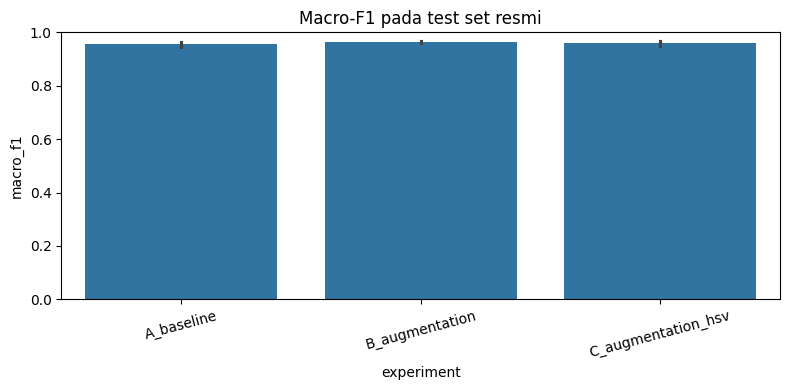

In [ ]:
summary = results_df.groupby("experiment").agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    accuracy_mean=("accuracy", "mean"),
    balanced_acc_mean=("balanced_accuracy", "mean"),
    inference_ms_mean=("inference_ms_per_image", "mean"),
    n_runs=("seed", "count")
).reset_index()
display(summary)
summary.to_csv(RUN_DIR / "metrics_summary.csv", index=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="experiment", y="macro_f1", errorbar="sd")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.title("Macro-F1 pada test set resmi")
plt.tight_layout()
plt.show()

## 11. Confusion matrix, precision/recall per kelas, dan kesalahan prediksi

Pilih model dengan **validation macro-F1 tertinggi**, bukan berdasarkan test score. Tampilkan metrik detailnya pada test set resmi.

Model terpilih berdasarkan VALIDASI: B_augmentation seed 123
                 precision    recall  f1-score   support

         matang     0.8657    0.9831    0.9206        59
         mentah     1.0000    1.0000    1.0000        99
setengah-matang     1.0000    1.0000    1.0000       122
 terlalu-matang     0.9885    0.9053    0.9451        95

       accuracy                         0.9733       375
      macro avg     0.9635    0.9721    0.9664       375
   weighted avg     0.9760    0.9733    0.9736       375



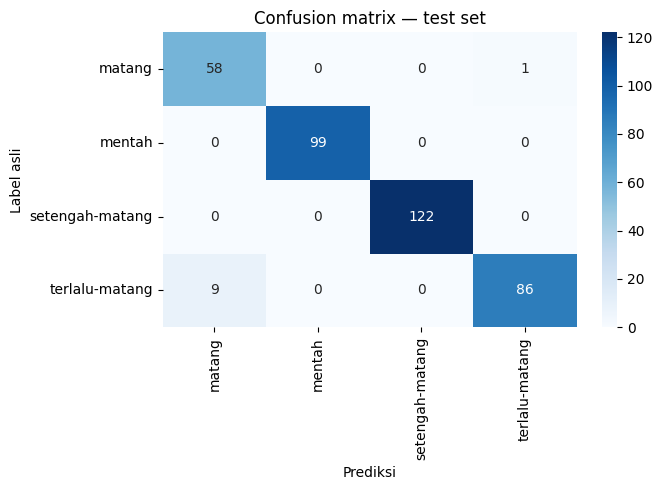

Jumlah kesalahan: 10


,path,class_name,prediction
51,/content/banana_ripeness_data/test/matang/mata...,matang,terlalu-matang
283,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
285,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
295,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
306,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
316,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
318,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
325,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
337,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang
370,/content/banana_ripeness_data/test/terlalu-mat...,terlalu-matang,matang


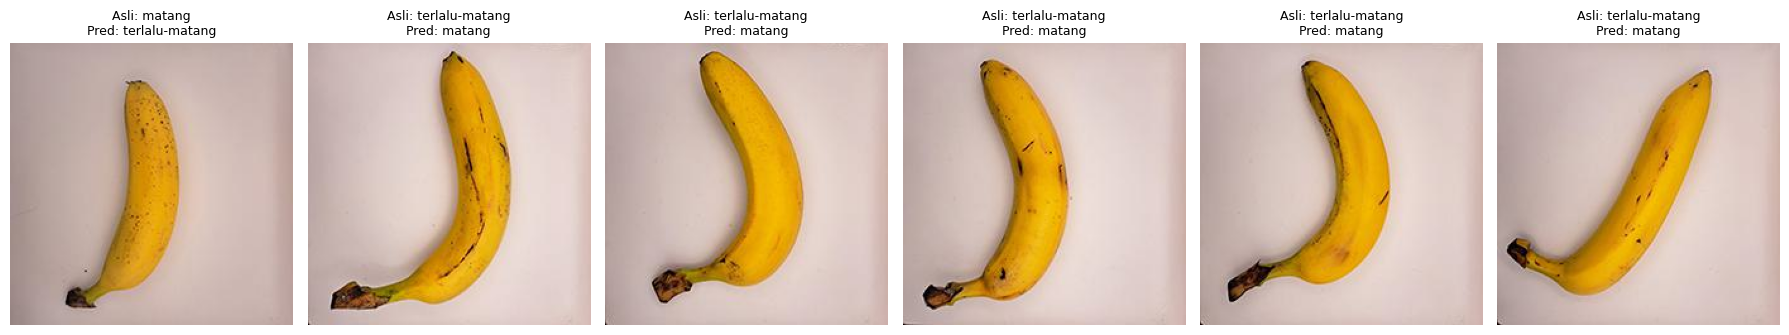

In [ ]:
chosen_row = results_df.sort_values("val_macro_f1", ascending=False).iloc[0]
chosen_exp = next(x for x in EXPERIMENTS if x["name"] == chosen_row["experiment"])
chosen_model = keras.models.load_model(chosen_row["checkpoint"])
chosen_test_ds = make_dataset(test_df, use_hsv=chosen_exp["use_hsv"])
chosen_prob = chosen_model.predict(chosen_test_ds, verbose=0)
chosen_pred = chosen_prob.argmax(axis=1)

print("Model terpilih berdasarkan VALIDASI:", chosen_row["experiment"],
      "seed", chosen_row["seed"])
print(classification_report(test_df.target.to_numpy(), chosen_pred,
                            labels=range(4), target_names=CLASS_NAMES,
                            digits=4, zero_division=0))
cm = confusion_matrix(test_df.target.to_numpy(), chosen_pred, labels=range(4))
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi")
plt.ylabel("Label asli")
plt.title("Confusion matrix — test set")
plt.tight_layout()
plt.show()

errors = test_df.loc[chosen_pred != test_df.target.to_numpy()].copy()
errors["prediction"] = [CLASS_NAMES[i] for i in chosen_pred[chosen_pred != test_df.target.to_numpy()]]
print("Jumlah kesalahan:", len(errors))
display(errors[["path", "class_name", "prediction"]].head(15))

if len(errors):
    display_n = min(6, len(errors))
    fig, axes = plt.subplots(1, display_n, figsize=(3 * display_n, 3.5))
    if display_n == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, errors.head(display_n).iterrows()):
        ax.imshow(keras.utils.load_img(row["path"], target_size=IMG_SIZE))
        ax.set_title(f"Asli: {row['class_name']}\nPred: {row['prediction']}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 12. Uji foto ponsel pada pencahayaan terang/redup (opsional sampai data tersedia)

Agar sesuai proposal, kumpulkan foto **pisang yang sama** pada dua kondisi cahaya, masing-masing berlabel kelas kematangan yang benar. Struktur folder yang diharapkan:

```text
/content/banana_phone/
  terang/<nama-kelas-1>/*.jpg
  terang/<nama-kelas-2>/*.jpg
  ...
  redup/<nama-kelas-1>/*.jpg
  redup/<nama-kelas-2>/*.jpg
  ...
```

Nama subfolder kelas harus sama persis dengan `CLASS_NAMES` yang tampil pada notebook. Foto ini **tidak boleh dipakai untuk training**. Foto ponsel berukuran kecil memberi estimasi yang tidak stabil; jelaskan jumlah foto dan keterbatasan pengujiannya.

In [ ]:
from pathlib import Path

RUN_DIR = Path(
    "/content/drive/MyDrive/Deep Learning/UAS"
)

print("Folder tersedia:", RUN_DIR.exists())
print(
    "File metrik tersedia:",
    (RUN_DIR / "metrics_all_runs.csv").exists()
)

print(
    "Jumlah checkpoint:",
    len(list(RUN_DIR.glob(
        "*_seed*/selected_model.keras"
    )))
)

Folder tersedia: True
File metrik tersedia: True
Jumlah checkpoint: 9


In [ ]:
required = [
    "test_df",
    "CLASS_NAMES",
    "BATCH_SIZE",
    "read_image",
    "hsv_histogram"
]

for name in required:
    print(
        name,
        "OK" if name in globals() else "BELUM ADA"
    )

test_df OK
CLASS_NAMES OK
BATCH_SIZE OK
read_image OK
hsv_histogram OK



Menguji A_baseline, seed 42
  Original: Macro-F1 = 0.9628
  Terang: Macro-F1 = 0.9569
  Redup: Macro-F1 = 0.9516

Menguji A_baseline, seed 123
  Original: Macro-F1 = 0.9595
  Terang: Macro-F1 = 0.9505
  Redup: Macro-F1 = 0.9542

Menguji A_baseline, seed 2026
  Original: Macro-F1 = 0.9435
  Terang: Macro-F1 = 0.9348
  Redup: Macro-F1 = 0.9308

Menguji B_augmentation, seed 42
  Original: Macro-F1 = 0.9599
  Terang: Macro-F1 = 0.9573
  Redup: Macro-F1 = 0.9562

Menguji B_augmentation, seed 123
  Original: Macro-F1 = 0.9664
  Terang: Macro-F1 = 0.9566
  Redup: Macro-F1 = 0.9597

Menguji B_augmentation, seed 2026
  Original: Macro-F1 = 0.9632
  Terang: Macro-F1 = 0.9506
  Redup: Macro-F1 = 0.9579

Menguji C_augmentation_hsv, seed 42
  Original: Macro-F1 = 0.9661
  Terang: Macro-F1 = 0.9537
  Redup: Macro-F1 = 0.9410

Menguji C_augmentation_hsv, seed 123
  Original: Macro-F1 = 0.9628
  Terang: Macro-F1 = 0.9530
  Redup: Macro-F1 = 0.9520

Menguji C_augmentation_hsv, seed 2026
  Original: Ma

,experiment,condition,macro_f1_mean,macro_f1_std,accuracy_mean,balanced_accuracy_mean,delta_f1_mean,n_runs
0,A_baseline,Original,0.9553,0.0103,0.9644,0.9598,0.0000,3
1,A_baseline,Redup,0.9455,0.0129,0.9582,0.9415,-0.0098,3
2,A_baseline,Terang,0.9474,0.0114,0.9573,0.9549,-0.0079,3
3,B_augmentation,Original,0.9632,0.0033,0.9707,0.9677,0.0000,3
4,B_augmentation,Redup,0.9579,0.0018,0.9671,0.9580,-0.0053,3
5,B_augmentation,Terang,0.9549,0.0037,0.9636,0.9616,-0.0083,3
6,C_augmentation_hsv,Original,0.9585,0.0103,0.9671,0.9624,0.0000,3
7,C_augmentation_hsv,Redup,0.9464,0.0055,0.9582,0.9451,-0.0121,3
8,C_augmentation_hsv,Terang,0.9471,0.0107,0.9573,0.9542,-0.0114,3


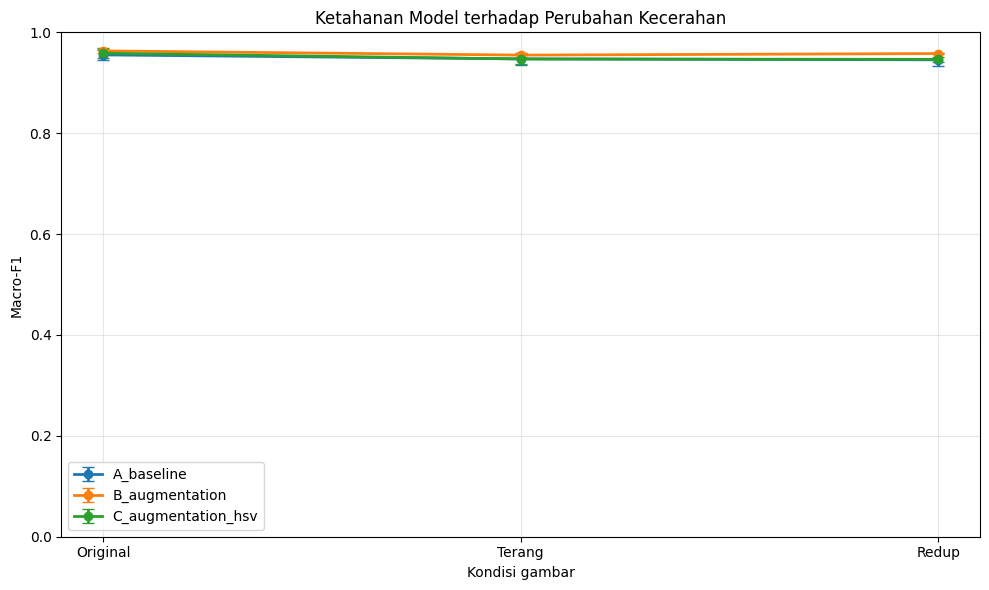


Selesai! Hasil disimpan di: /content/drive/MyDrive/Deep Learning/UAS


In [ ]:

# 12. Uji ketahanan terhadap perubahan kecerahan sintetis
# Menggunakan 375 gambar test dan checkpoint hasil training final

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Lokasi hasil training final di Google Drive
RUN_DIR = Path("/content/drive/MyDrive/Deep Learning/UAS")

# Memuat metadata sembilan model yang sudah dilatih
results_df = pd.read_csv(RUN_DIR / "metrics_all_runs.csv")

# Pastikan data uji resmi tersedia
assert len(test_df) == 375, (
    f"Jumlah data test seharusnya 375, terbaca {len(test_df)}"
)

# Gamma < 1: lebih terang; gamma > 1: lebih redup
CONDITIONS = {
    "Original": 1.0,
    "Terang": 0.7,
    "Redup": 1.5
}

def make_lighting_dataset(df, gamma, use_hsv=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["path"].astype(str).to_numpy(),
        df["target"].astype("int32").to_numpy()
    ))

    # Menggunakan preprocessing yang sama seperti saat training
    ds = ds.map(read_image, num_parallel_calls=tf.data.AUTOTUNE)

    def apply_lighting(image, label):
        image = tf.pow(image, tf.constant(gamma, tf.float32))
        image = tf.clip_by_value(image, 0.0, 1.0)
        return image, label

    ds = ds.map(
        apply_lighting,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Histogram HSV harus dihitung ulang setelah perubahan cahaya
    if use_hsv:
        ds = ds.map(
            lambda image, label: (
                {
                    "image_input": image,
                    "hsv_input": hsv_histogram(image)
                },
                label
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


# Evaluasi ketiga skenario pada seluruh random seed
rows = []
y_true = test_df["target"].to_numpy()

for _, run in results_df.iterrows():
    exp_name = str(run["experiment"])
    seed = int(run["seed"])
    use_hsv = str(run["use_hsv"]).lower() == "true"

    checkpoint = Path(str(run["checkpoint"]))
    if not checkpoint.exists():
        checkpoint = (
            RUN_DIR / f"{exp_name}_seed{seed}" / "selected_model.keras"
        )

    if not checkpoint.exists():
        raise FileNotFoundError(f"Checkpoint tidak ditemukan: {checkpoint}")

    print(f"\nMenguji {exp_name}, seed {seed}")

    model = keras.models.load_model(checkpoint, compile=False)

    for condition, gamma in CONDITIONS.items():
        ds = make_lighting_dataset(
            test_df, gamma=gamma, use_hsv=use_hsv
        )

        probabilities = model.predict(ds, verbose=0)
        y_pred = np.argmax(probabilities, axis=1)

        rows.append({
            "experiment": exp_name,
            "seed": seed,
            "condition": condition,
            "n_images": len(y_true),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, y_pred
            ),
            "macro_f1": f1_score(
                y_true, y_pred,
                labels=list(range(len(CLASS_NAMES))),
                average="macro",
                zero_division=0
            )
        })

        print(
            f"  {condition}: Macro-F1 = "
            f"{rows[-1]['macro_f1']:.4f}"
        )

    del model
    keras.backend.clear_session()


# Simpan hasil seluruh model dan seed
lighting_df = pd.DataFrame(rows)

# Selisih terhadap gambar original pada model dan seed yang sama
original_scores = lighting_df[
    lighting_df["condition"] == "Original"
][["experiment", "seed", "macro_f1"]].rename(
    columns={"macro_f1": "original_f1"}
)

lighting_df = lighting_df.merge(
    original_scores, on=["experiment", "seed"]
)

lighting_df["delta_f1"] = (
    lighting_df["macro_f1"] - lighting_df["original_f1"]
)

lighting_df.to_csv(
    RUN_DIR / "lighting_all_runs.csv", index=False
)


# Rata-rata dan standar deviasi dari 3 seed
summary = lighting_df.groupby(
    ["experiment", "condition"], as_index=False
).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std"),
    accuracy_mean=("accuracy", "mean"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
    delta_f1_mean=("delta_f1", "mean"),
    n_runs=("seed", "count")
)

summary.to_csv(
    RUN_DIR / "lighting_summary.csv", index=False
)

print("\nRingkasan hasil uji pencahayaan:")
display(summary.round(4))


# Grafik perbandingan Macro-F1
plt.figure(figsize=(10, 6))
condition_order = ["Original", "Terang", "Redup"]

for experiment, group in summary.groupby("experiment"):
    group = group.set_index("condition").loc[condition_order]

    plt.errorbar(
        condition_order,
        group["macro_f1_mean"],
        yerr=group["macro_f1_std"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=experiment
    )

plt.title("Ketahanan Model terhadap Perubahan Kecerahan")
plt.xlabel("Kondisi gambar")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RUN_DIR / "lighting_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("\nSelesai! Hasil disimpan di:", RUN_DIR)

## 13. Grad-CAM pada MobileNetV2

Grad-CAM dipakai sebagai **visualisasi pendukung**, bukan bukti bahwa model mempelajari kematangan dengan benar. Contoh di bawah merekonstruksi jalur classification head memakai bobot model terlatih sehingga bisa diterapkan pada arsitektur gabungan HSV.

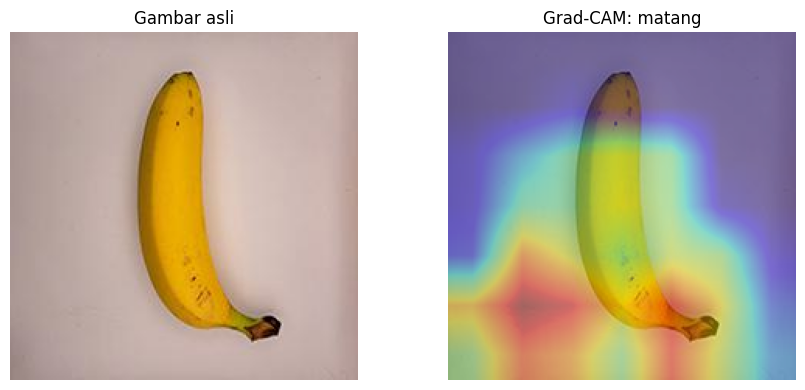

In [ ]:
def show_gradcam(model, image_path, use_hsv=False):
    # Temukan nested MobileNetV2 di dalam model terlatih.
    backbones = [layer for layer in model.layers
                 if isinstance(layer, keras.Model) and "mobilenet" in layer.name.lower()]
    if not backbones:
        raise ValueError("MobileNetV2 tidak ditemukan pada model.")
    backbone = backbones[0]
    conv_extractor = keras.Model(
        backbone.input, [backbone.get_layer("out_relu").output, backbone.output]
    )
    pil_img = keras.utils.load_img(image_path, target_size=IMG_SIZE)
    image01 = keras.utils.img_to_array(pil_img).astype("float32") / 255.0
    img_tensor = tf.convert_to_tensor(image01[None, ...])

    with tf.GradientTape() as tape:
        scaled = model.get_layer("mobilenet_scaling")(img_tensor)
        conv_map, cnn_map = conv_extractor(scaled, training=False)
        pooled = model.get_layer("global_avg")(cnn_map)
        if use_hsv:
            hist = hsv_histogram(tf.convert_to_tensor(image01))[None, :]
            pooled = model.get_layer("feature_concat")([pooled, hist])
        x = model.get_layer("dense_128")(pooled)
        x = model.get_layer("dropout_head")(x, training=False)
        probs = model.get_layer("class_probs")(x)
        predicted_class = tf.argmax(probs[0])
        score = probs[:, predicted_class]
    grads = tape.gradient(score, conv_map)
    if grads is None:
        raise RuntimeError("Grad-CAM gagal menghitung gradien.")
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.reduce_sum(conv_map * weights, axis=-1)[0]
    cam = tf.maximum(cam, 0)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
    plt.figure(figsize=(9, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image01); plt.axis("off"); plt.title("Gambar asli")
    plt.subplot(1, 2, 2)
    plt.imshow(image01)
    plt.imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
    plt.axis("off")
    plt.title(f"Grad-CAM: {CLASS_NAMES[int(predicted_class.numpy())]}")
    plt.tight_layout(); plt.show()

show_gradcam(chosen_model, test_df.iloc[0]["path"], use_hsv=bool(chosen_exp["use_hsv"]))

## 14. Prediksi satu foto baru

Model klasifikasi mengeluarkan **empat probabilitas kelas**. Tidak ada bounding box karena tugasnya adalah klasifikasi foto pisang.

In [ ]:
def predict_one(model, image_path, use_hsv=False):
    pil_img = keras.utils.load_img(image_path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(pil_img).astype("float32") / 255.0
    if use_hsv:
        x = {"image_input": arr[None, ...],
             "hsv_input": hsv_histogram(tf.convert_to_tensor(arr))[None, :].numpy()}
    else:
        x = arr[None, ...]
    proba = model.predict(x, verbose=0)[0]
    print("Prediksi:", CLASS_NAMES[int(proba.argmax())])
    display(pd.DataFrame({"kelas": CLASS_NAMES, "probabilitas": proba}).sort_values(
        "probabilitas", ascending=False
    ))

predict_one(chosen_model, test_df.iloc[0]["path"], use_hsv=bool(chosen_exp["use_hsv"]))

Prediksi: matang


,kelas,probabilitas
0,matang,9.996788e-01
3,terlalu-matang,3.141490e-04
2,setengah-matang,7.007041e-06
1,mentah,8.622712e-10


## 15. Unduh hasil

Notebook menyimpan checkpoint per eksperimen/seed, CSV hasil test, ringkasan hasil, dan (jika tersedia) evaluasi foto ponsel. Pastikan semua file dipindahkan ke Drive sebelum runtime Colab diakhiri.

In [ ]:
from google.colab import files
import shutil

archive_path = shutil.make_archive("/content/banana_mobilenet_results", "zip", RUN_DIR)
print("ZIP hasil:", archive_path)
files.download(archive_path)

ZIP hasil: /content/banana_mobilenet_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Panduan penulisan hasil UAS

- **Dataset:** catat nama dataset dan split train/validation/test yang sebenarnya, distribusi kelas, dan kemungkinan foto yang sangat mirip antara split.
- **Tiga skenario:** bandingkan A, B, dan C dengan split dan konfigurasi yang sama. Kontribusi HSV lebih tepat dinilai dari perbandingan **C vs B**, sedangkan augmentasi dari **B vs A**.
- **Training:** jelaskan penggunaan pretrained ImageNet, class weighting, early stopping, fine-tuning bertahap, jumlah epoch aktual, dan tiga seed.
- **Evaluasi:** utamakan macro-F1, sertakan accuracy, balanced accuracy, precision/recall per kelas, confusion matrix, waktu inferensi, dan rerata ± simpangan baku antarseed.
- **Robustness:** jika foto ponsel tersedia, cantumkan banyaknya foto per kondisi cahaya, label acuan, serta keterbatasan jumlah objek/jenis pisang.
- **Grad-CAM:** gunakan contoh benar/salah untuk interpretasi, bukan pengganti evaluasi numerik.
- **Kesimpulan:** laporkan hasil yang benar-benar diperoleh, termasuk bila augmentasi/HSV *tidak* meningkatkan metrik.

**Referensi metodologi:** [TensorFlow — transfer learning](https://www.tensorflow.org/tutorials/images/transfer_learning), [MobileNetV2 API](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2), Pangestu (2023) — Banana Ripeness Image (DOI: 10.34820/FK2/GJBZ0X).

**Catatan:** Notebook telah diperiksa secara statis, tetapi **belum dijalankan untuk training** karena dataset dan GPU Colab tidak tersedia dalam sesi penyusunan ini. Periksa struktur ZIP dan hasil setiap sel ketika dijalankan di Colab.